# BRD4 natural-product docking: quality control and grid sensitivity
**CHPC terminal results, 26 November 2026 | BD1 (2YEL), BD2 (2YEM)**

This self-contained notebook reproduces the quantitative figures from the reported CHPC terminal outputs for 15 natural products. Primary grids and +4 Å expanded dimensions were evaluated with Vina 1.2.3, seed 2024, exhaustiveness 32, four CPUs, up to nine poses, and pH 7.5 preparations. Original grids remain primary. The source data below are transcribed terminal summaries, not independently re-run docking calculations. Expanded BD2 scores are reconstructed to 0.001 kcal/mol from reported expanded BD1 scores and BD1−BD2 differences; published summary statistics are checked. The 4 Å residue contacts are geometric contacts, not confirmed hydrogen bonds. No experimental binding or selectivity is implied. The reference redocking RMSD threshold is 2 Å; candidate pose differences and boundary margins use descriptive thresholds only. Single-seed grid comparisons do not establish multi-seed reproducibility.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr, kendalltau
from IPython.display import display, Image
from io import BytesIO

OUT = Path('figures'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.labelsize':15,'axes.labelweight':'bold','axes.linewidth':1.5,'xtick.labelsize':11,'ytick.labelsize':11,'legend.fontsize':11,'legend.frameon':False,'lines.linewidth':2,'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','svg.fonttype':'none'})
B='#2563eb'; D='#d97706'; G='#555555'
def finish(fig,name):
    fig.tight_layout()
    fig.savefig(OUT/(name+'.svg'),bbox_inches='tight')
    fig.savefig(OUT/(name+'.png'),dpi=600,bbox_inches='tight')
    # Compact inline SVG for notebook; exported PNGs retain 600 dpi.
    from IPython.display import SVG
    display(SVG(filename=str(OUT/(name+'.svg'))))
    plt.close(fig)
def panel(ax,letter): ax.text(-.12,1.04,letter,transform=ax.transAxes,fontsize=15,fontweight='bold')
ids=[f'NP{i:02d}' for i in range(1,16)]
x=np.arange(15)
orig1=[-7.731,-6.737,-6.513,-6.894,-6.719,-7.233,-6.329,-7.271,-8.174,-8.370,-8.519,-8.710,-7.842,-7.201,-7.260]
orig2=[-8.111,-6.861,-6.917,-6.624,-7.136,-7.755,-6.221,-6.960,-7.876,-8.408,-8.290,-8.299,-8.128,-7.409,-7.389]
exp1=[-8.049,-6.699,-6.446,-6.981,-6.670,-7.331,-6.212,-7.257,-8.337,-8.293,-8.221,-8.499,-7.962,-7.424,-7.203]
exp_delta=[.002,.105,.784,-.329,.363,.454,.029,-.260,.065,.117,.087,.640,.435,.010,.174]
exp2=np.round(np.array(exp1)-exp_delta,3)
df=pd.DataFrame(dict(Ligand=ids,BD1_original=orig1,BD2_original=orig2,BD1_expanded=exp1,BD2_expanded=exp2,diameter=[15.174,12.575,11.267,13.298,10.197,12.710,12.414,9.284,13.213,15.170,13.228,13.324,13.757,16.485,12.782],heavy_atoms=[34,27,26,25,21,23,27,21,43,42,43,42,29,33,24],formal_charge=[1]+[0]*14,partial_charge=[1.002,.002,0,.001,.001,.001,0,.001,0,-.001,-.001,0,-.003,-.001,.001],conversion_RMSD=[.00050,.00049,.00049,.00051,.00053,.00054,.00048,.00052,.00052,.00052,.00052,.00052,.00057,.00050,.00049],torsdof=[6,6,8,8,3,5,6,2,9,9,9,9,7,11,6],BD1_pose_RMSD=[.133,.114,.095,.704,4.493,1.895,.256,.236,.091,.154,.103,.090,.214,9.177,.184],BD2_pose_RMSD=[.425,.176,.094,1.106,.072,.107,1.896,.149,10.978,10.453,11.132,9.922,.225,.757,.118]))
df.to_csv(OUT/'ligand_summary.csv',index=False)
assert len(df)==15 and (abs(df.partial_charge-df.formal_charge)<=.05).all()
print('Ligand records:',len(df),'| charge QC: 15/15 | source identity QC: 15/15 (reported)')
print('Original poses: 270; expanded poses: 269; structural QC: 539/539 (reported).')

Ligand records: 15 | charge QC: 15/15 | source identity QC: 15/15 (reported)
Original poses: 270; expanded poses: 269; structural QC: 539/539 (reported).


## 1. Ligand preparation and search-space geometry
Diameters are maximum intramolecular distances of the prepared ligand, not a proof of fit for every conformer or orientation. Charge errors are PDBQT charge minus formal charge. Coordinate RMSD represents format conversion, not docking accuracy.

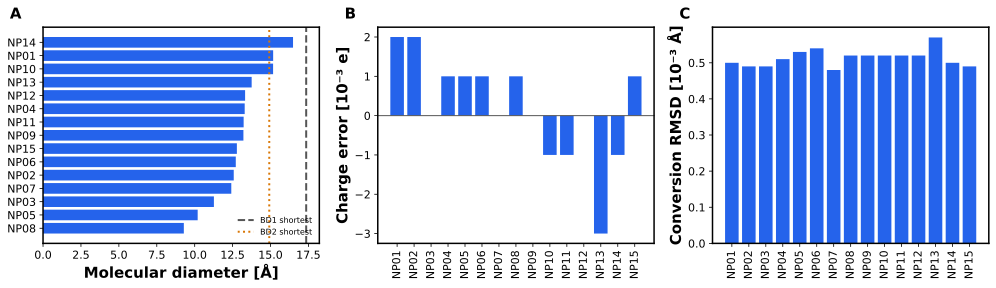

In [2]:
fig,ax=plt.subplots(1,3,figsize=(14,4.2))
order=np.argsort(df.diameter)
ax[0].barh(x,df.diameter.iloc[order],color=B); ax[0].set_yticks(x,df.Ligand.iloc[order]); ax[0].axvline(17.352,color=G,ls='--',label='BD1 shortest'); ax[0].axvline(14.917,color=D,ls=':',label='BD2 shortest'); ax[0].set_xlabel('Molecular diameter [Å]'); ax[0].legend(loc='lower right',fontsize=8)
ax[1].bar(x,1000*(df.partial_charge-df.formal_charge),color=B); ax[1].axhline(0,color=G,lw=1); ax[1].set_ylabel('Charge error [10⁻³ e]'); ax[1].set_xticks(x,ids,rotation=90)
ax[2].bar(x,1000*df.conversion_RMSD,color=B); ax[2].set_ylabel('Conversion RMSD [10⁻³ Å]'); ax[2].set_xticks(x,ids,rotation=90)
for a,l in zip(ax,'ABC'): panel(a,l)
finish(fig,'01_ligand_qc')

## 2. Reference redocking validation
Symmetry-corrected heavy-atom RMSD to crystallographic WSH; no alignment. Both top-ranked poses pass under each grid protocol.

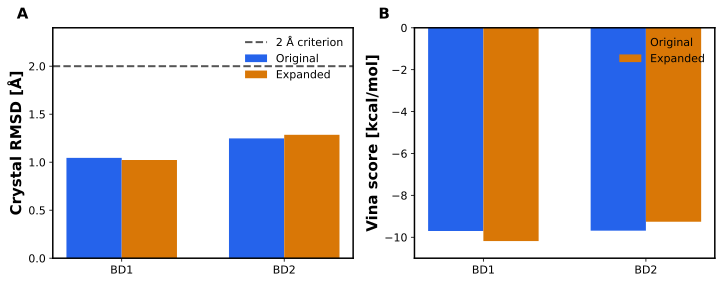

In [3]:
fig,ax=plt.subplots(1,2,figsize=(10.2,4.1)); q=np.arange(2); w=.34
for k,(a,b,ylabel) in enumerate([([1.045,1.248],[1.023,1.285],'Crystal RMSD [Å]'),([-9.700,-9.687],[-10.182,-9.260],'Vina score [kcal/mol]')]):
    ax[k].bar(q-w/2,a,w,label='Original',color=B); ax[k].bar(q+w/2,b,w,label='Expanded',color=D); ax[k].set_xticks(q,['BD1','BD2']); ax[k].set_ylabel(ylabel); panel(ax[k],'AB'[k])
ax[0].axhline(2,color=G,ls='--',label='2 Å criterion'); ax[0].set_ylim(0,2.4); ax[0].legend(); ax[1].legend(loc='upper right'); ax[1].set_ylim(-11,0)
finish(fig,'02_redocking_validation')

## 3. Primary candidate docking scores
The WSH reference is plotted separately from the natural products; more negative scores are more favourable within this scoring model.

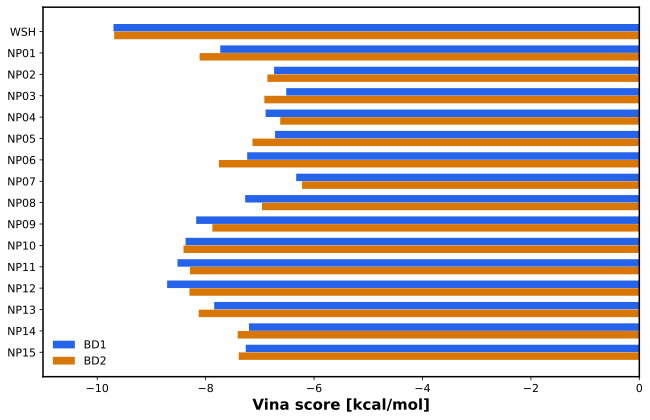

In [4]:
fig,ax=plt.subplots(figsize=(9.2,6)); y=np.arange(16); a=[-9.700]+orig1; b=[-9.687]+orig2
ax.barh(y-.18,a,.35,color=B,label='BD1'); ax.barh(y+.18,b,.35,color=D,label='BD2'); ax.set_yticks(y,['WSH']+ids); ax.invert_yaxis(); ax.set_xlabel('Vina score [kcal/mol]'); ax.legend(loc='lower left'); ax.set_xlim(-11,0); finish(fig,'03_primary_scores')

## 4. Score and ranking sensitivity
Reconstructed BD2 expanded scores are checked against the reported summary. Ties are not interpreted as biological selectivity.

Domain  Spearman  p_rho  Kendall  p_tau    bias    MAE   RMSE  max_abs  top5_overlap
   BD1    0.9500    0.0   0.8286    0.0 -0.0054 0.1291 0.1578    0.318             4
   BD2    0.9607    0.0   0.8667    0.0 -0.1251 0.1560 0.2798    0.840             4


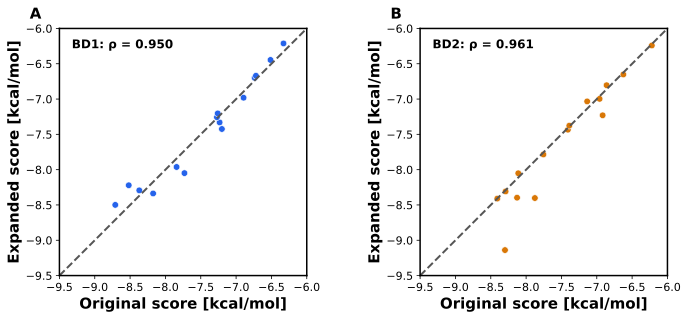

In [5]:
stats=[]
fig,ax=plt.subplots(1,2,figsize=(10.2,4.6))
for k,d in enumerate(['BD1','BD2']):
    a=df[d+'_original'].to_numpy(); b=df[d+'_expanded'].to_numpy(); delta=b-a; rho,p=spearmanr(a,b); tau,pt=kendalltau(a,b)
    topa=set(np.argsort(a)[:5]); topb=set(np.argsort(b)[:5]); stats.append([d,rho,p,tau,pt,delta.mean(),abs(delta).mean(),np.sqrt(np.mean(delta**2)),abs(delta).max(),len(topa&topb)])
    ax[k].scatter(a,b,s=44,color=[B,D][k],edgecolors='white',linewidth=.6); ax[k].plot([-9.5,-6],[-9.5,-6],ls='--',color=G); ax[k].set(xlim=(-9.5,-6),ylim=(-9.5,-6),xlabel='Original score [kcal/mol]',ylabel='Expanded score [kcal/mol]'); ax[k].set_aspect('equal'); ax[k].text(.05,.92,f'{d}: ρ = {rho:.3f}',transform=ax[k].transAxes,fontweight='bold'); panel(ax[k],'AB'[k])
s=pd.DataFrame(stats,columns=['Domain','Spearman','p_rho','Kendall','p_tau','bias','MAE','RMSE','max_abs','top5_overlap']); print(s.round(4).to_string(index=False)); s.to_csv(OUT/'score_statistics.csv',index=False)
np.testing.assert_allclose(s.Spearman,[.9500,.9607],atol=.0001); np.testing.assert_allclose(s.MAE,[.1291,.1560],atol=.0001)
finish(fig,'04_score_agreement')

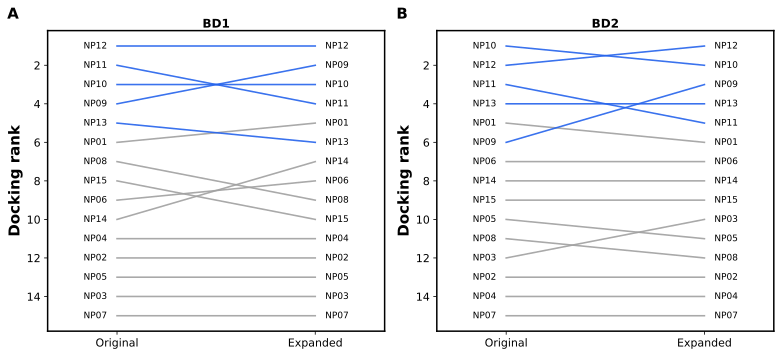

In [6]:
fig,ax=plt.subplots(1,2,figsize=(11,5.1));
for k,d in enumerate(['BD1','BD2']):
    a=df[d+'_original'].rank(method='min'); b=df[d+'_expanded'].rank(method='min');
    for i in range(15):
        ax[k].plot([0,1],[a[i],b[i]],color=B if i in [8,9,10,11,12] else '#a0a0a0',alpha=.9,lw=1.6); ax[k].text(-.05,a[i],ids[i],ha='right',va='center',fontsize=9); ax[k].text(1.05,b[i],ids[i],ha='left',va='center',fontsize=9)
    ax[k].set(xlim=(-.35,1.35),ylim=(15.8,.2),xticks=[0,1],xticklabels=['Original','Expanded'],ylabel='Docking rank'); ax[k].yaxis.set_major_locator(MaxNLocator(integer=True)); ax[k].text(.5,1.01,d,transform=ax[k].transAxes,ha='center',fontweight='bold'); panel(ax[k],'AB'[k])
finish(fig,'05_rank_robustness')

Sign reversals: NP07, NP09, NP11, NP12


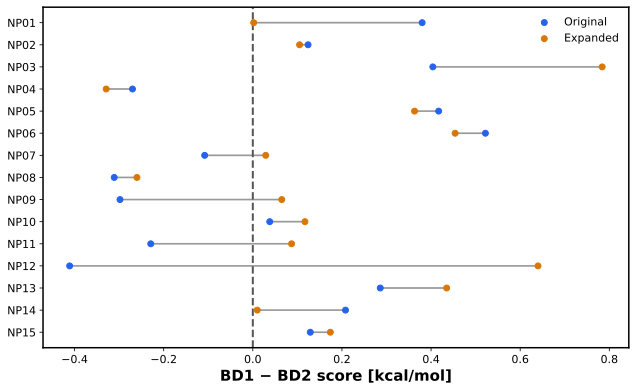

In [7]:
fig,ax=plt.subplots(figsize=(9,5.6)); o=np.array(orig1)-orig2; e=np.array(exp_delta); y=np.arange(15)
for i in range(15): ax.plot([o[i],e[i]],[i,i],color='#999999',lw=1.7)
ax.scatter(o,y,color=B,label='Original',zorder=3); ax.scatter(e,y,color=D,label='Expanded',zorder=3); ax.axvline(0,color=G,ls='--'); ax.set_yticks(y,ids); ax.invert_yaxis(); ax.set_xlabel('BD1 − BD2 score [kcal/mol]'); ax.legend(); print('Sign reversals:',', '.join(df.Ligand[o*e<0])); finish(fig,'06_domain_preference')

## 5. Binding-mode sensitivity
Symmetry-corrected top-ranked heavy-atom RMSD without fitting, as reported from CHPC. RMSD > 2 Å flags a descriptive pose change; not a failure criterion for unknown binding poses.

Stable top poses: 13 /15 BD1; 11 /15 BD2


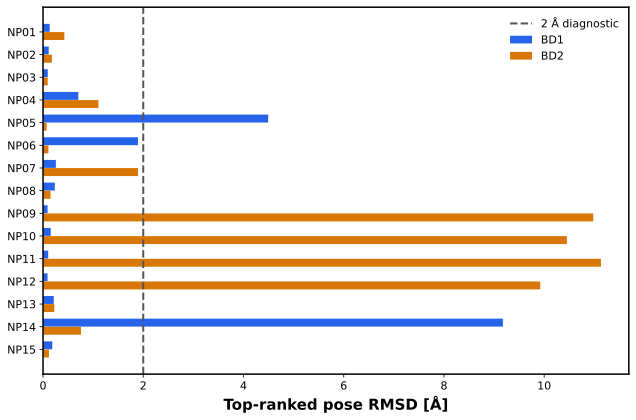

In [8]:
fig,ax=plt.subplots(figsize=(9,6)); y=np.arange(15); ax.barh(y-.18,df.BD1_pose_RMSD,.35,color=B,label='BD1'); ax.barh(y+.18,df.BD2_pose_RMSD,.35,color=D,label='BD2'); ax.axvline(2,color=G,ls='--',label='2 Å diagnostic'); ax.set_yticks(y,ids); ax.invert_yaxis(); ax.set_xlabel('Top-ranked pose RMSD [Å]'); ax.legend(); print('Stable top poses:',sum(df.BD1_pose_RMSD<=2),'/15 BD1;',sum(df.BD2_pose_RMSD<=2),'/15 BD2'); finish(fig,'07_pose_rmsd')

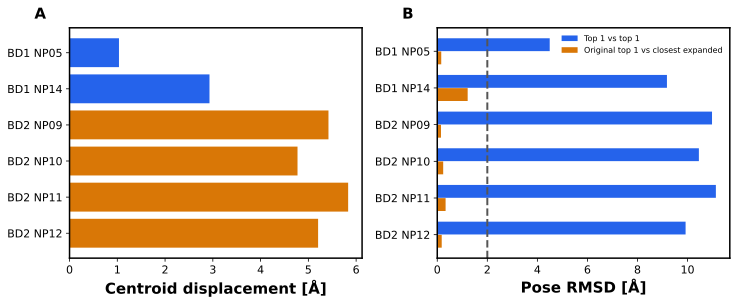

In [9]:
alt=pd.DataFrame({'Case':['BD1 NP05','BD1 NP14','BD2 NP09','BD2 NP10','BD2 NP11','BD2 NP12'],'Top1_RMSD':[4.493,9.177,10.978,10.453,11.132,9.922],'centroid_shift':[1.035,2.930,5.421,4.773,5.833,5.204],'recovered_RMSD':[.159,1.215,.149,.237,.333,.178],'expanded_mode':[2,2,3,4,3,5],'reverse_RMSD':[.278,2.322,7.614,8.408,7.224,7.036],'minimum_all_pairs':[.103,.106,.138,.120,.133,.178],'original_WSH_distance':[1.715,1.831,1.548,1.932,1.425,1.443],'expanded_WSH_distance':[.866,3.316,6.576,6.563,6.785,6.251],'original_WSH_Jaccard':[.538,.786,.786,.714,.769,.846],'expanded_WSH_Jaccard':[.538,.500,.500,.500,.467,.467],'cross_grid_Jaccard':[1,.5,.667,.583,.462,.538]}); alt.to_csv(OUT/'alternative_pose_summary.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(10.4,4.4)); y=np.arange(6)
ax[0].barh(y,alt.centroid_shift,color=[B]*2+[D]*4); ax[0].set_xlabel('Centroid displacement [Å]'); ax[1].barh(y-.18,alt.Top1_RMSD,.35,color=B,label='Top 1 vs top 1'); ax[1].barh(y+.18,alt.recovered_RMSD,.35,color=D,label='Original top 1 vs closest expanded'); ax[1].set_xlabel('Pose RMSD [Å]'); ax[1].axvline(2,color=G,ls='--'); ax[1].legend(fontsize=8,loc='upper right')
for a,l in zip(ax,'AB'): a.set_yticks(y,alt.Case); a.invert_yaxis(); panel(a,l)
finish(fig,'08_alternative_pose_recovery')

## 6. Pocket occupancy and residue contact comparison
Contact sets are geometric heavy-atom contacts within 4 Å. Greater WSH similarity does not establish the correct pose.

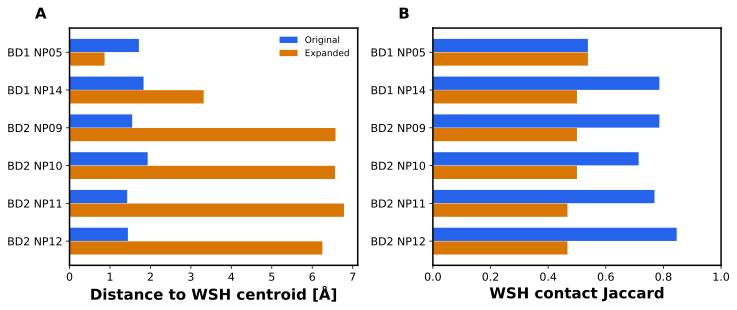

In [10]:
fig,ax=plt.subplots(1,2,figsize=(10.4,4.5)); y=np.arange(6)
for k,(a,b,l) in enumerate([(alt.original_WSH_distance,alt.expanded_WSH_distance,'Distance to WSH centroid [Å]'),(alt.original_WSH_Jaccard,alt.expanded_WSH_Jaccard,'WSH contact Jaccard')]):
    ax[k].barh(y-.18,a,.35,color=B,label='Original'); ax[k].barh(y+.18,b,.35,color=D,label='Expanded'); ax[k].set_yticks(y,alt.Case); ax[k].invert_yaxis(); ax[k].set_xlabel(l); panel(ax[k],'AB'[k])
ax[0].legend(fontsize=9); ax[1].set_xlim(0,1); finish(fig,'09_pocket_occupancy')

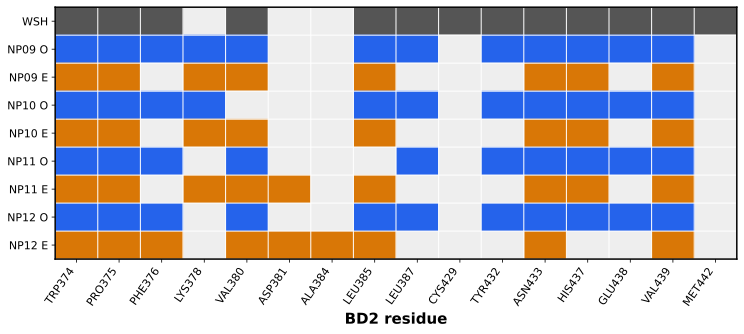

In [11]:
contacts={'WSH':[433,429,438,437,385,387,442,376,375,374,432,380,439], 'NP09 O':[433,438,437,385,387,378,376,375,374,432,380,439], 'NP09 E':[433,437,385,378,375,374,380,439], 'NP10 O':[433,438,437,385,387,378,376,375,374,432,439], 'NP10 E':[433,437,385,378,375,374,380,439], 'NP11 O':[433,438,437,387,376,375,374,432,380,439], 'NP11 E':[433,381,437,385,378,375,374,380,439], 'NP12 O':[433,438,437,385,387,376,375,374,432,380,439], 'NP12 E':[384,433,381,385,376,375,374,380,439]}
names={374:'TRP',375:'PRO',376:'PHE',378:'LYS',380:'VAL',381:'ASP',384:'ALA',385:'LEU',387:'LEU',429:'CYS',432:'TYR',433:'ASN',437:'HIS',438:'GLU',439:'VAL',442:'MET'}
res=sorted(names); matrix=np.array([[int(r in v) for r in res] for v in contacts.values()]); labels=[names[r]+str(r) for r in res]; pd.DataFrame(matrix,index=contacts,columns=labels).to_csv(OUT/'BD2_contact_matrix.csv')
from matplotlib.colors import ListedColormap
fig,ax=plt.subplots(figsize=(10.5,4.8)); typed=matrix*np.array([1]+[2,3]*4)[:,None]; ax.imshow(typed,aspect='auto',cmap=ListedColormap(['#eeeeee',G,B,D]),vmin=0,vmax=3); ax.set_xticks(range(len(res)),labels,rotation=55,ha='right'); ax.set_yticks(range(len(contacts)),list(contacts)); ax.set_xticks(np.arange(-.5,len(res),1),minor=True); ax.set_yticks(np.arange(-.5,len(contacts),1),minor=True); ax.grid(which='minor',color='white',linewidth=1); ax.tick_params(which='minor',bottom=False,left=False); ax.set_xlabel('BD2 residue'); finish(fig,'10_contact_fingerprint')

## 7. Effective-grid boundary assessment
Effective grid dimensions follow the previously used ceiling-to-0.375 Å convention. Near boundary means heavy-atom clearance < 1 Å with a 0.001 Å numerical tolerance for outside classification. These are diagnostic thresholds.

Domain Protocol  poses  near  outside  top1_near  median_top1_margin  near_pct
   BD1 Original    135    47        0          4              2.2065 34.814815
   BD1 Expanded    135    14        0          1              3.8915 10.370370
   BD2 Original    135    54        0          8              0.9335 40.000000
   BD2 Expanded    134    20        0          4              2.6060 14.925373


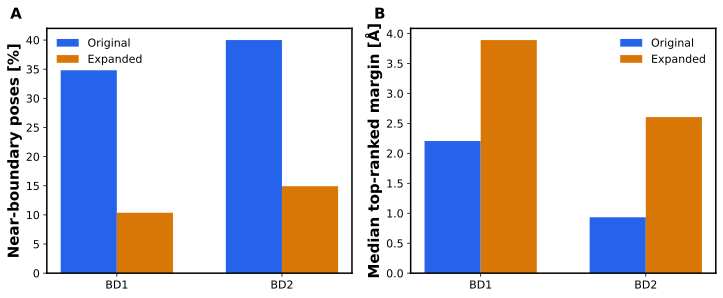

In [12]:
bound=pd.DataFrame({'Domain':['BD1','BD1','BD2','BD2'],'Protocol':['Original','Expanded']*2,'poses':[135,135,135,134],'near':[47,14,54,20],'outside':[0,0,0,0],'top1_near':[4,1,8,4],'median_top1_margin':[2.2065,3.8915,.9335,2.606]}); bound['near_pct']=100*bound.near/bound.poses; bound.to_csv(OUT/'boundary_summary.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(10.2,4.3)); q=np.arange(2); w=.34
for k,(col,lab) in enumerate([('near_pct','Near-boundary poses [%]'),('median_top1_margin','Median top-ranked margin [Å]')]):
    for i,prot in enumerate(['Original','Expanded']): ax[k].bar(q+(i-.5)*w,bound[bound.Protocol==prot][col],w,label=prot,color=[B,D][i]);
    ax[k].set_xticks(q,['BD1','BD2']); ax[k].set_ylabel(lab); ax[k].legend(); panel(ax[k],'AB'[k])
print(bound.to_string(index=False)); finish(fig,'11_boundary_comparison')

## Interpretation and limitations
Ranking was strongly concordant under the two grid sizes (Spearman 0.9500 and 0.9607); 4/5 top candidates were retained in each domain. NP10–NP12 were top-five in all four rankings. Top-ranked pose stability was 13/15 (BD1) and 11/15 (BD2). Four compounds reversed the sign of the domain score difference. All six original binding configurations were recovered in lower-ranked expanded modes, and the four BD2 biflavonoids showed displacement away from the WSH centroid while retaining some pocket contacts. The expanded protocol reduced near-boundary poses; none of the 539 reported poses lay outside the calculated effective grid. These are computational diagnostics, not experimental validation. Full coordinate-level reproduction and structural superpositions require the raw CHPC archive. NP01 optimization convergence was not supplied in the visible terminal output. No fabricated coordinates or energy landscape calculations are used.